In [121]:
import zipfile
with zipfile.ZipFile("/content/drive/MyDrive/datasets/data.zip","r") as zip_file:
  zip_file.extractall("/content")

In [122]:
import glob
import cv2
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



In [123]:

# glioma = []
# path = './Data/glioma/*jpg'
# for f in glob.iglob(path):
#   img = cv2.imread(f)
#   img = cv2.resize(img,(128,128))
#   b, g, r = cv2.split(img)
#   img = cv2.merge([r, g, b])
#   glioma.append(img)

In [124]:
# print("nomber des images dans glioma :",len(glioma))
# import os


In [125]:
# meningioma = []
# path = './Data/meningioma/*jpg'
# for f in glob.iglob(path):
#   img = cv2.imread(f)
#   img = cv2.resize(img,(128,128))
#   b, g, r = cv2.split(img)
#   img = cv2.merge([r, g, b])
#   meningioma.append(img)

In [126]:

# print("nomber des images dans meningioma :",len(meningioma))


In [127]:
# notumor = []
# path = './Data/notumor/*jpg'
# for f in glob.iglob(path):
#   img = cv2.imread(f)
#   img = cv2.resize(img,(128,128))
#   b, g, r = cv2.split(img)
#   img = cv2.merge([r, g, b])
#   notumor.append(img)

In [128]:
# print("nomber des images dans notumor :",len(notumor))



In [129]:
# pituitary = []
# path = './Data/pituitary/*jpg'
# for f in glob.iglob(path):
#   img = cv2.imread(f)
#   img = cv2.resize(img,(128,128))
#   b, g, r = cv2.split(img)
#   img = cv2.merge([r, g, b])
#   pituitary.append(img)

In [130]:
# print("nomber des images dans pityutary :",len(pituitary))


In [131]:


# pituitary = np.array(pituitary)
# notumor = np.array(notumor)
# glioma = np.array(glioma)
# meningioma = np.array(meningioma)

In [132]:
# pituitary.shape

In [133]:
extention_images = {".jpeg", ".jpg", ".bmp", ".png"}
DATA_DIREC = Path("./Data/")
files_images = []
classes = ["notumor","pituitary","meningioma","glioma"]

for class_name in classes:
    class_path = DATA_DIREC/class_name

    files = [
        file for file in class_path.rglob("*")
        if file.is_file()
        and file.suffix.lower() in extention_images
    ]

    files_images.extend(
        (file, class_name) for file in files
    )

print(" nombre total d'images :", len(files_images))

 nombre total d'images : 7023


In [134]:
# creation un dataframe des images :

df_images = pd.DataFrame(files_images,columns=["path", "label"])

print(df_images.head())

print("\nNombre d'images par classe :")
print(df_images["label"].value_counts())

                          path    label
0  Data/notumor/Tr-no_0382.jpg  notumor
1  Data/notumor/Tr-no_1564.jpg  notumor
2  Data/notumor/Te-no_0367.jpg  notumor
3  Data/notumor/Tr-no_1144.jpg  notumor
4  Data/notumor/Tr-no_0995.jpg  notumor

Nombre d'images par classe :
label
notumor       2000
pituitary     1757
meningioma    1645
glioma        1621
Name: count, dtype: int64


**Charger les images avec OpenCV**

In [135]:
# Redimensionner les images à une taille fixe (ex. 224×224) à l'aide de la bibliothèque OpenCV:

images = []
labels = []

for file_path, label in files_images:
    try:
        image = cv2.imread(str(file_path))

        if image is None:
            print("-- image illisible :", file_path)
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        image = cv2.resize(image, (224, 224))

        images.append(image)
        labels.append(label)

    except Exception as error:
        print("Erreur :", file_path, error)
        continue

print("Images chargees :", len(images))
print("Labels charges :", len(labels))

Images chargees : 7023
Labels charges : 7023


In [136]:
# Convertir les listes d'images et d'étiquettes en tableaux NumPy pour les rendre exploitables par le modèle:

X = np.array(images, dtype=np.uint8)
y = np.array(labels)

print("X shape :", X.shape)
print("y shape :", y.shape)
print("Classes :", np.unique(y))

X shape : (7023, 224, 224, 3)
y shape : (7023,)
Classes : ['glioma' 'meningioma' 'notumor' 'pituitary']


glioma : 1621 images
meningioma : 1645 images
notumor : 2000 images
pituitary : 1757 images


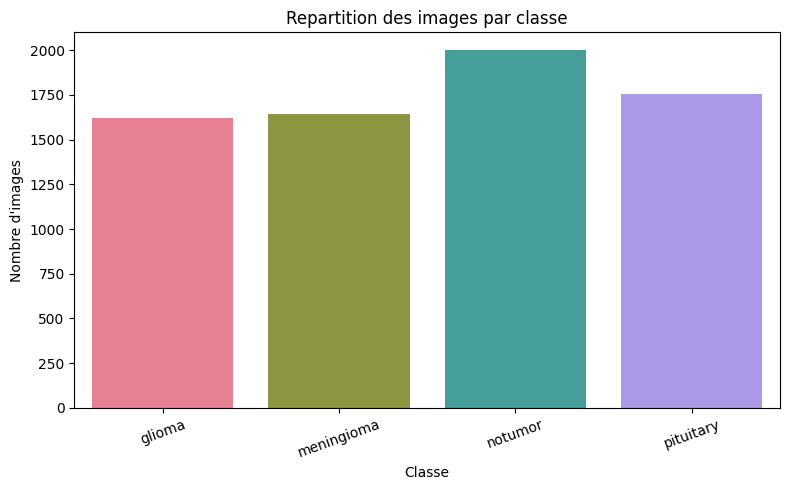

In [ ]:
# Conmter le nombre d'images par classe*

classes, counts = np.unique(y, return_counts=True)

# Afficher les résultats
for classe, nombre in zip(classes, counts):
    print(f"{classe} : {nombre} images")

plt.figure(figsize=(8, 5))

sns.barplot(x=classes, y=counts, hue=classes, palette="husl",legend=False)

plt.title("Repartition des images par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

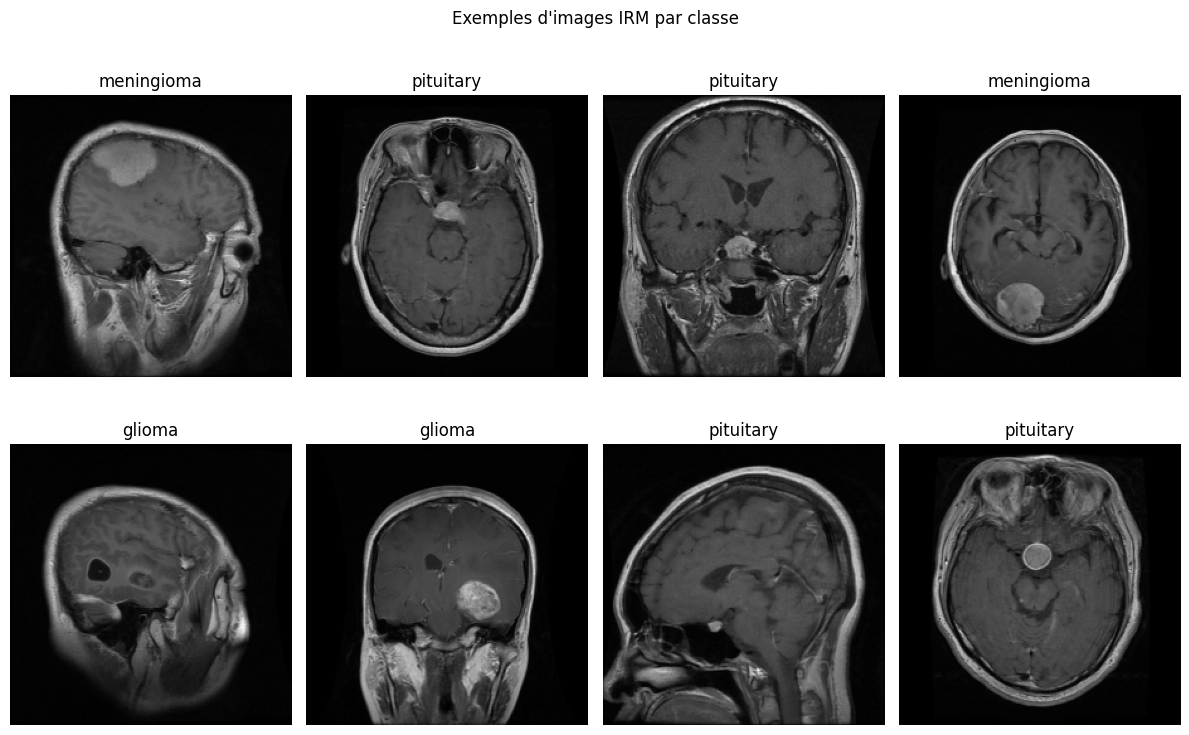

In [ ]:
# Afficher 8 images aleatoires

np.random.seed(42)

nombre_images = min(8, len(X))
indices = np.random.choice(len(X), size=nombre_images, replace=False)

plt.figure(figsize=(12, 8))

for position, index in enumerate(indices):
    plt.subplot(2, 4, position + 1)
    plt.imshow(X[index])
    plt.title(y[index])
    plt.axis("off")

plt.suptitle("Exemples d'images IRM par classe")
plt.tight_layout()
plt.show()


In [ ]:
# -----------------------------------------

print("Type des donnees :", X.dtype)
print("Valeur minimale des pixels :", X.min())
print("Valeur maximale des pixels :", X.max())
print("Dimensions des images :", X.shape[1:])


Type des données : uint8
Valeur minimale des pixels : 0
Valeur maximale des pixels : 255
Dimensions des images : (224, 224, 3)


In [ ]:
from sklearn.model_selection import train_test_split

# Premiere division : :70 % train et 30% temporaire
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Deuxieme division : 15 % validation et 15 % test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Verifier les dimensions

print("X_train :", X_train.shape)
print("X_val   :", X_val.shape)
print("X_test  :", X_test.shape)
print("----------------------")
print("y_train :", y_train.shape)
print("y_val   :", y_val.shape)
print("y_test  :", y_test.shape)


X_train : (4916, 224, 224, 3)
X_val   : (1053, 224, 224, 3)
X_test  : (1054, 224, 224, 3)
y_train : (4916,)
y_val   : (1053,)
y_test  : (1054,)


In [ ]:
# encoding

from sklearn.preprocessing import LabelEncoder

# Creer et entrainer l'encodeur sur les labels
encoder = LabelEncoder()
encoder.fit(y)

# Transformer les labels de chaque ensemble en nombres
y_train_encoded = encoder.transform(y_train)
y_val_encoded = encoder.transform(y_val)
y_test_encoded = encoder.transform(y_test)

# Garder les noms des classes dans le bon ordre
class_names = encoder.classes_
num_classes = len(class_names)

print("Classes :", class_names)
print("Nombre de classes :", num_classes)

print("\nExemples de labels avant encodage :", y_train[:10])
print("Exemples de labels apres encodage :", y_train_encoded[:10])


Classes : ['glioma' 'meningioma' 'notumor' 'pituitary']
Nombre de classes : 4

Exemples de labels avant encodage : ['glioma' 'notumor' 'meningioma' 'glioma' 'pituitary' 'glioma' 'notumor'
 'notumor' 'pituitary' 'meningioma']
Exemples de labels après encodage : [0 2 1 0 3 0 2 2 3 1]


In [ ]:
#  augmentation :

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

data_augmentation = keras.Sequential(
    [
        layers.RandomRotation(0.03),
        layers.RandomZoom(0.05),
        layers.RandomTranslation(
            height_factor=0.03,
            width_factor=0.03
        )
    ],
    name="data_augmentation"
)

print("Data augmentation preparee.")


Data augmentation préparée.


# création et entraînement du modèle CNN



In [ ]:
# Créer le modele CNN


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Creer l'architecture du CNN
model = keras.Sequential([

    layers.Input(shape=(224, 224, 3)),

    # normaliser les pixels : de [0, 255] vers [0, 1]
    layers.Rescaling(1.0 / 255),

    # augmentation des donnees pendant l'entrainement
    data_augmentation,

    # premire extraction de caracteristiques

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Deuxieme extraction de caracteristiques
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Troisieme extraction de caracteristiques
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Transformer les caracteristiques en vecteur
    layers.GlobalAveragePooling2D(),

    # Couche de classification
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    # Prediction des 4 classes
    layers.Dense(num_classes, activation="softmax")
])

# Afficher la structure de modele
model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,764 (397.52 KB)

 Trainable params: 101,764 (397.52 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compiler le modele


model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modele compile avec succes.")


Modèle compilé avec succès.


In [ ]:

from tensorflow import keras

# 1. Arreter l'entraenement si le modele ne s'ameliore plus
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

# 2. Sauvegarder automatiquement le meilleur modele
model_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath="neurovision_best.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

# 3. Reduire le learning rate si la validation stagne
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

callbacks_list = [
    early_stopping,
    model_checkpoint,
    reduce_lr
]

print("Les callbacks sont prits.")


Les callbacks sont prêts.


In [ ]:
# Entrainer le modèle


history = model.fit(
    X_train,
    y_train_encoded,
    validation_data=(X_val, y_val_encoded),
    epochs=20,
    batch_size=32,
    callbacks=callbacks_list,
    verbose=1
)



Epoch 1/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.3503 - loss: 1.2834
Epoch 1: val_loss improved from None to 1.35496, saving model to neurovision_best.keras

Epoch 1: finished saving model to neurovision_best.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 11s 62ms/step - accuracy: 0.4367 - loss: 1.1837 - val_accuracy: 0.3751 - val_loss: 1.3550 - learning_rate: 0.0010
Epoch 2/20
153/154 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.6023 - loss: 0.9893
Epoch 2: val_loss did not improve from 1.35496
154/154 ━━━━━━━━━━━━━━━━━━━━ 9s 61ms/step - accuracy: 0.6225 - loss: 0.9429 - val_accuracy: 0.3732 - val_loss: 1.9093 - learning_rate: 0.0010
Epoch 3/20
153/154 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.6658 - loss: 0.8458
Epoch 3: val_loss did not improve from 1.35496

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
154/154 ━━━━━━━━━━━━━━━━━━━━ 8s 55ms/step - accuracy: 0.6625 - loss: 0.8423 - val_accuracy: 0.4179 - val_loss: 1.5426 - learning_rate: 0.

In [ ]:

# Charger le meilleur modèle sauvegardé
best_model = keras.models.load_model("neurovision_best.keras")

print("Meilleur modele charge avec succees")

# evaluer le meilleur modèle sur les données de test
test_loss, test_accuracy = best_model.evaluate(
    X_test,
    y_test_encoded,
    verbose=1
)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.2%}")


Meilleur modèle charge avec succees.
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.6509 - loss: 0.8586
Test Loss     : 0.8586
Test Accuracy : 65.09%


33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
              precision    recall  f1-score   support

      glioma       0.84      0.44      0.58       243
  meningioma       0.65      0.52      0.58       247
     notumor       0.64      0.92      0.76       300
   pituitary       0.58      0.67      0.62       264

    accuracy                           0.65      1054
   macro avg       0.68      0.64      0.63      1054
weighted avg       0.68      0.65      0.64      1054



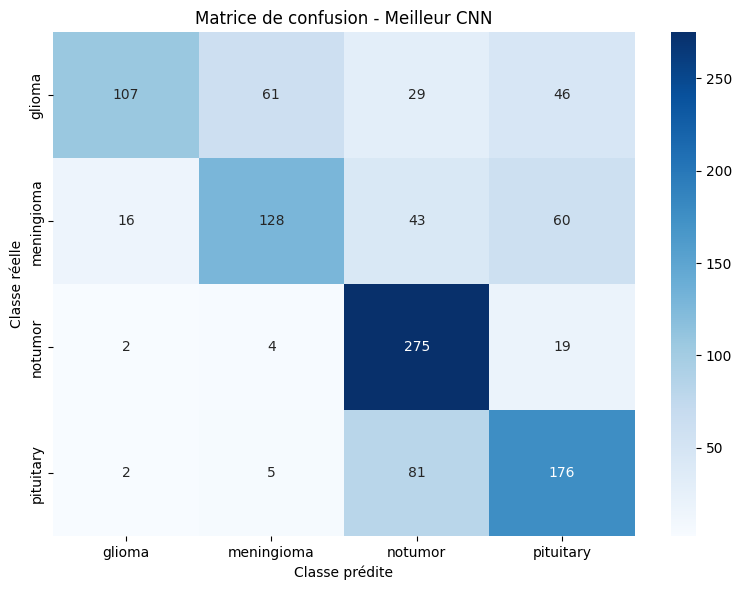

In [ ]:

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Predictions du meilleur modele
y_pred_proba = best_model.predict(X_test, verbose=1)
y_pred = np.argmax(y_pred_proba, axis=1)

# Rapport de classification
print(classification_report(
    y_test_encoded,
    y_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    zero_division=0
))

# Matrice de confusion
cm = confusion_matrix(
    y_test_encoded,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Matrice de confusion - Meilleur CNN")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.tight_layout()
plt.show()


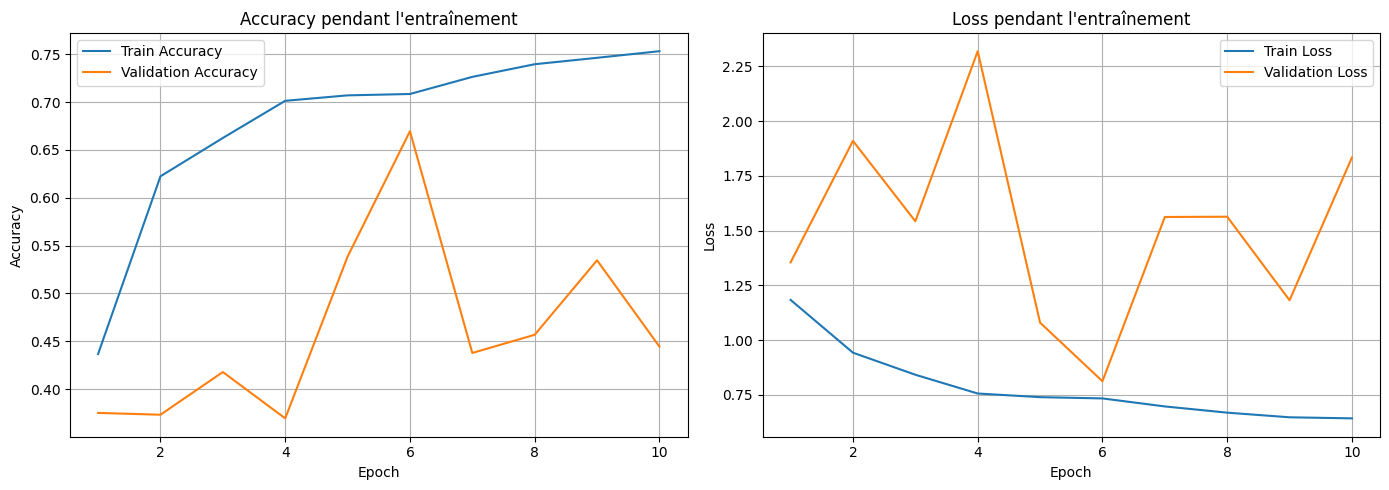

In [ ]:
# Visualiser les résultats de l'entraînement


train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs_range = range(1, len(train_accuracy) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique de l'accuracy
axes[0].plot(epochs_range, train_accuracy, label="Train Accuracy")
axes[0].plot(epochs_range, val_accuracy, label="Validation Accuracy")
axes[0].set_title("Accuracy pendant l'entraînement")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Graphique de la loss
axes[1].plot(epochs_range, train_loss, label="Train Loss")
axes[1].plot(epochs_range, val_loss, label="Validation Loss")
axes[1].set_title("Loss pendant l'entraînement")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [174]:
# Évaluer le modèle sur les données de test


test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test_encoded,
    verbose=1
)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.2%}")


33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6509 - loss: 0.8586
Test Loss     : 0.8586
Test Accuracy : 65.09%


In [ ]:

model.save("neurovision_cnn.keras")

print("Modèle sauvegarde avec succes")


Modèle sauvegardé avec succès.


In [ ]:

modele_charge = keras.models.load_model("neurovision_cnn.keras")

modele_charge.summary()
